In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

np.set_printoptions(precision=3, suppress=True)

In [2]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
print(X_all.shape, y_all.shape, iris.target_names)

(150, 4) (150,) ['setosa' 'versicolor' 'virginica']


a, b, c = 5, 8, 7

In [3]:
from matplotlib.patches import Patch, Circle
from matplotlib.colors import LinearSegmentedColormap, to_rgb

SPECIES = ["setosa", "versicolor", "virginica"]
COLORS  = ["#2a78d6", "#eb6834", "#1baf7a"]   # one colour per species, used in every plot
MARKERS = ["o", "s", "^"]                     # ...and one shape (easier to read on a projector)
INK, INK2, MUTED, LINE, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "lines.linewidth": 2,
    "axes.edgecolor": LINE, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelcolor": INK2, "axes.labelsize": 10,
    "xtick.color": LINE, "ytick.color": LINE, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "legend.frameon": True, "legend.facecolor": SURFACE, "legend.edgecolor": "none",
    "legend.framealpha": 0.88, "legend.fontsize": 9,
})

In [ ]:
def _scatter_species(ax, X, y):
    for k in range (3):
        m = y == k
        ax.scatter(X[m,0], X[m,1], s=42, c=COLORS[k], marker=MARKERS[k],
                    edgecolors=SURFACE, linewidths=0.9, label=SPECIES[k], zorder=3)
def _tint(color, amount):
    c, s = to_rgb(color), to_rgb(SURFACE)
    return tuple(si + amount * (ci -si) for ci, si in zip(c, s))

def _petal_axes(ax):
    ax.set_xlabel("petal length (cm)")
    ax.set_xlabel("petal width (cm)")
    ax.set_xlim(0.5, 7.5)
    ax.set_ylim(-0.2, 2.9)

def plot_flowers(X, y):
    fig, ax = plt.subplots(figsize=(5.8, 4.2))
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    ax.set_title("150 iris flowers, two petal measurements")
    ax.legend(loc='upper left')
    plt.show()

def plot_regions(predict, X, y, target, title='', ax=None, legend=True):
    """Shade where predict(X_cm) > 0.5, i.e. where the model answers 'yes, this is a <target>'."""
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(5.8, 4.2))
    g0, g1 = np.meshgrid(np.linspace(0.5, 7.5, 350), np.linspace(-0.2, 2.9, 350))
    P = np.asarray(predict(np.c_[g0.ravel(), g1.ravel()]), dtype=float).reshape(g0.shape)
    tint = _tint(COLORS[target], 0.24)
    ax.contourf(g0, g1, (P > 0.5).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURFACE, tint], zorder=2)
    if P.min() < 0.5 <P.max():
        ax.contour(g0, g1, P, levels=[0.5], colors=INK, linewidths=1.4, zorder=2)
    ax.grid(False)
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    acc = np.mean((np.asarray(predict(X), dtype=float).ravel() > 0.5) == (y == target))
    ax.set_title(f'{title}\naccuracy {acc:.1%}' if title else f'accuracy {acc:.1%}')
    if legend:
        handles = ax.get_legend_handles_labels()[0]
        handles.append(Patch(facecolor=tint, edgecolor='none', label=f'model says:{SPECIES[target]}'))
        ax.legend(handles=handles, loc='upper left')
    if standalone:
        plt.show()

def show_perceptron(w, b, mistakes, X, y, target):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.15]})
    epochs = np.arange(1, len(mistakes) + 1)
    ax1.plot(epochs, mistakes, color=INK2, marker='o', markersize=5.5, markeredgecolor=SURFACE, clip_on=False)
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('mistakes during the epoch')
    ax1.set_ylim(0, max(10, max(mistakes) * 1.15))
    ax1.set_title(f'Perceptron learning: {SPECIES[target]} vs. the rest\nmistakes per epoch')
    plot_regions(lambda Xq: (Xq @ w +b > 0).astype(float), X, y, target, title='Final decision boundary', ax=ax2)
    plt.tight_layout()
    plt.show

def draw_network(sizes, in_labels, out_labels, out_colors, hidden_labels=None, title=''):
    xs = np.arange(len(sizes)) * 2.4
    ys = [np.linspace((s - 1) / 2, s) * 0.9 for s in sizes]
    top = max(len(1) for l in ys) * 0.45 + 0.4
    fig, ax = plt.subplots(figsize=(7.2, 0.55 * max(sizes) + 1.5))
    for i in range(len(sizes) -1):
        for ya in ys[i]:
            for yb in ys[i+1]:
                ax.plot([xs[i], xs[i + 1]], [ya, yb], color=LINE, lw=0.9, zorder=1)
    r = 0.24
    for i, (x, layer) in enumerate(zip(xs, ys)):
        for j, yj in enumerate(layer):
            if i == len(sizes) - 1:
                face, edge = _tint(out_colors[j], 0.3), out_colors[j]
            else:
                face, edge = ('#f0efec' if i else SURFACE), INK2
            ax.add_path(Circle((x, yj), r, facecolor=face, edgecolor=edge, lw=1.6, zorder=3))
            if i == 0:
                ax.text(x - r - 0.15, yj, in_labels[j], ha='right', va='center', color=INK)
            elif i == len(sizes -1):
                ax.text(x - r - 0.15, yj, out_labels[j], ha='left', va='center', color=INK)
            elif hidden_labels:
                ax.text(x, yj, hidden_labels[j], ha='center', va='center', color=INK, fontsize=9, zorder=4)
    names = ['inputs'] + ['hidden layer'] * (len(sizes) - 2) + ['output layer']
    bottom = min(l.min() for l in ys) - r - 0.25
    for x, name, s in zip(xs, names, sizes):
        unit = 'value' if name == 'inputs' else 'neuron'
        ax.text(x, bottom, f"{name}\n{s} {unit}{'s' if > 1 else ''}", ha='center', va='top', color=MUTED, fontsize=9)
    ax.set_aspect('equal')
    ax.set_xlim(xs[0] - 2.6, xs[-1] + 2.4)
    ax.set_ylim(bottom - 0.75, -bottom + 0.2)
    if title:
        ax.set_title(title)
    plt.show()

    def show_training(losses, predict, X, y, target):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11,4.2), gridspec_kw={'width_ratios':[1, 1.15]})
        ax1.plot(np.arange(1, len(losses) + 1), losses, color=INK2)
        ax1.set_xlabel('epoch')
        ax1.set_ylabel('cross entropy loss')
        ax1.set_ylim(0, max(losses) * 1.08)
        ax1.set_title('1  The loss while it learns')
        plot_regions(predict, X, y, target, title='2  What it learned', ax=ax2)
        plt.tight_layout()
        plt.show()

    def plot_hidden_space(H, y, params, target):
        if H.shape[1] != 2:
            print(f'The hidden layer has {H.shape[1]} neurons: too many dimensions to draw. Use n_hidden=2')
            return
        W2, b2 = params[2], params[3]
        fig, ax = plt.subplots(figsize=(5.8, 4.8))
        g0, g1 = np.meshgrid(np.linspace(-0.6, 1.06, 300), np.linspace(-0.6, 1.06, 300))
        Z = (np.c_[g0.ravel(), g1.ravel()] @ W2 + b2).reshape(g0.shape)
        tint = _tint(COLORS[target], 0.24)
        ax.contourf(g0, g1, (Z > 0).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURFACE, tint], zorder=0)
        ax.grid(False)
        _scatter_species(ax, H, y)
        ax.set_xlim(-0.6, 1.06)
        ax.set_ylim(-0.6, 1.06)
        ax.set_xlabel('h1 = the output of hidden neuron 1')
        ax.set_ylabel('h2 = the output of hidden neuron 2')
        ax.set_title('3  The flowers as the hidden layer sees them\n(the black line is output neuron) ')
        handles = ax.get_legend_handles_labels()[0]
        handles.append(Patch(facecolor=tint, edgecolor='none', label=f'model says: {SPECIES[target]}'))
        ax.legend(handles=handles, loc='best')
        plt.show()

SyntaxError: f-string: expecting '=', or '!', or ':', or '}' (604911716.py, line 86)

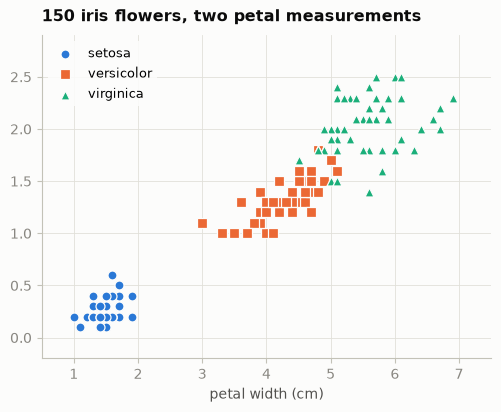

In [ ]:
X = X_all[:, 2:] # petal length, petal widtn (cm)
plot_flowers(X, y_all)

In [ ]:
X

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.7, 0.4],
       [1.4, 0.3],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.5, 0.1],
       [1.5, 0.2],
       [1.6, 0.2],
       [1.4, 0.1],
       [1.1, 0.1],
       [1.2, 0.2],
       [1.5, 0.4],
       [1.3, 0.4],
       [1.4, 0.3],
       [1.7, 0.3],
       [1.5, 0.3],
       [1.7, 0.2],
       [1.5, 0.4],
       [1. , 0.2],
       [1.7, 0.5],
       [1.9, 0.2],
       [1.6, 0.2],
       [1.6, 0.4],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.6, 0.2],
       [1.6, 0.2],
       [1.5, 0.4],
       [1.5, 0.1],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.2, 0.2],
       [1.3, 0.2],
       [1.4, 0.1],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.3, 0.3],
       [1.3, 0.3],
       [1.3, 0.2],
       [1.6, 0.6],
       [1.9, 0.4],
       [1.4, 0.3],
       [1.6, 0.2],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [4.7, 1.4],
       [4.5, 1.5],
       [4.9,

In [ ]:
def step(z):
    return (z > 0).astype(float)

def train_perceptron(X, y, epochs=30, lr=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes_per_epoch = []
    for epoch in range (epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            y_hat = step(X[i] @ w +b)
            update = lr * (y[i] - y_hat)
            w += update * X[i]
            b += update
            mistakes += int(y_hat != y[i])
        mistakes_per_epoch.append(mistakes)
    return w, b, mistakes_per_epoch

mistakes per epoch: [8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


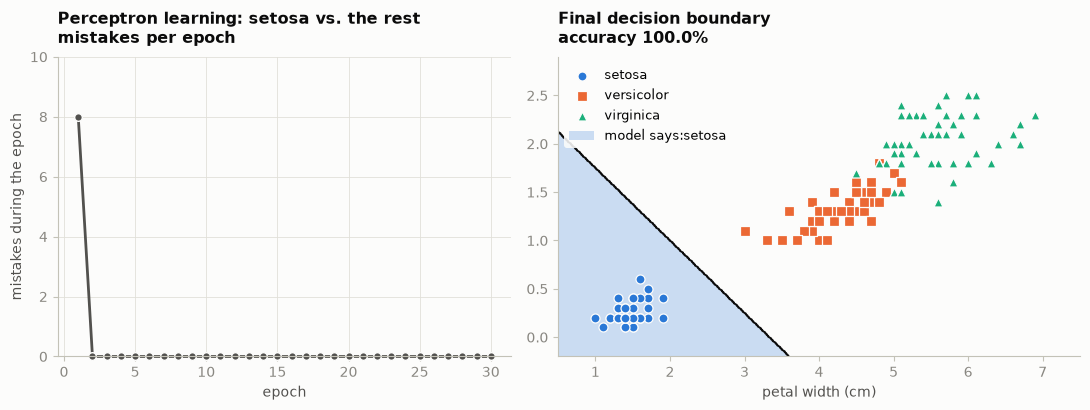

In [ ]:
y_setosa = (y_all == 0).astype(float)
w, b, mistakes = train_perceptron(X, y_setosa)
print('mistakes per epoch:', mistakes)
show_perceptron(w,b, mistakes, X, y_all, target=0)

mistakes per epoch: [65, 74, 70, 64, 59, 58, 53, 54, 52, 58, 56, 60, 56, 56, 52, 63, 56, 66, 48, 58, 60, 63, 56, 59, 49, 57, 54, 61, 63, 59]


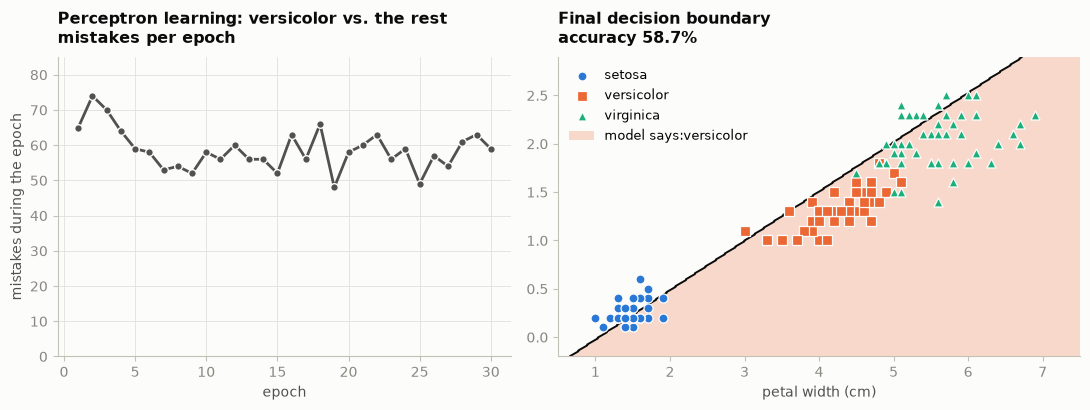

In [ ]:
y_versi = (y_all == 1).astype(float)
w, b, mistakes = train_perceptron(X, y_versi)
print('mistakes per epoch:', mistakes)
show_perceptron(w, b, mistakes, X, y_all, target=1)

In [ ]:
draw_network([2, 2, 1], in_labels['petal length', 'petal width'], hidden_labels=['h1', 'h2'],
            out_labels=['versicolor?'], out_colors=[COLORS[1]], title='Three perceptrons in two layers'
            )